# Esperienza 1

#### Gioele Antognoni, Marco Paoletti, Giovanni Zugarini

#### Strumentazione e materiali utilizzati
- basette, cavi coassiali, fili
- resistenze, capacitori
- Multimetro digitale 
- osiclloscopio digitale *RIGOL DS1054 Z*
- amplificatore operazione 741 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Metodologia di misura e incertezze strumentali
1) **Multimetro digitale:** La misura delle resistenze è affetta da un'incertezza indicata dal costruttore pari a $2\text{ digits} + 0.8\%$ del valore letto.
2) **Oscilloscopio:** Per la caratterizzazione dei segnali è stata impiegata la funzione statistica (`Measure > Stat. Sel. > Difference`), che restituisce media, deviazione standard della media e numero di campionamenti a partire dall'ultimo *reset* per 4 parametri configurabili. Ad ogni variazione delle condizioni di ingresso, la statistica è stata azzerata per isolare il nuovo regime e i risultati sono stati salvati tramite *screenshot* del display, associando alle misure l'incertezza statistica fornita dallo strumento.


#### L'amplificatore operazionale µA741
Per la realizzazione delle diverse configurazioni circuitali è stato impiegato l'amplificatore operazionale integrato **µA741**. Questo dispositivo analogico, alimentato in modalità duale, amplifica la differenza di tensione applicata ai suoi ingressi (invertente e non invertente) con un guadagno ad anello aperto molto elevato, un'alta impedenza di ingresso e una bassa impedenza di uscita. Sebbene in prima approssimazione il suo comportamento venga modellizzato tramite le ipotesi di operazionale ideale, nelle prove sperimentali emergono i suoi limiti fisici reali, quali la saturazione dell'uscita, la banda passante finita e lo *slew rate*.


### Struttura dell'esperienza
**Obiettivi:** Montare ed analizzare il comportamento di 3 tipi fondamentali di circuiti amplificatori, variando opportunamente frequenza e guadagno.

1. **Amplificatore open-loop**
    
    la configurazione più semplice che manifesta tutto il potere amplificatore dell'operazionale, permetterà di familiarizzare con gli oggetti e verificare il limite di saturazione.
2. **Amplificatore invertente** 
    
    il punto centrale del nostro studio riguarderà questo circuito, il quale grazie a due resistori opportunamente posizionati, permette di fissare il fattore di guadagno tra l'ampiezza del seganele in ingresso e quello in uscita. Studieremo questa configurazione per 2 diversi gudagni attesi, osservando il comportamento del fattore di aplificazione al variare della frequenza del segnale in ingresso.
3. **Amplificatore derivatore**

    Per ultimo si costruirà un circuito includendo un capacitore, posizionato a monte dell'operazionale, così da ottenere il uscita un seganle che rappresenta la derivata prima di quello in ingresso. Verificheremo inoltre che tale configurazione si comporta da filtro *passa-alto*.


### Open loop

La prima configurazione che andremo costruire sarà quella open loop, ovvero andremo ad analizzare il guadagno dell'op-amp in uso, confrontando la ddp tra i due ingressi con $V_{out}$, ci attendiamo che qualsiasi segnale in ingresso, il uscita vedremo un valore fisso a $V_{sat}$, l'unica informazione di $V_{in}$ che sopravvive sarà il suo segno.

<img src="open_loop.jpg" alt="schema amplificatore invertente" width="40%">


#### Posizionamento delle masse
Per riprodurre correttamente i circuiti è fondamentale il posizionamento delle masse, infatti la loro presenza garatisce che la *differenza di potenziale* che noi andiamo ad associare alle varie parti del circuito sia calcolata rispetto allo stesso riferimento ($V_{GND}$).

Innanzitutto abbiamo collegato il canale 1 del generatore DC, dal suo polo positivo, all'ingresso *4* del transistor ed il canale 2 all'ingresso *7*, dal polo negativo ed erogato da entrambi $5,0V$. Il generatore riesce a creare una ddp tra i 2 poli dei quali uno è la massa ($V_{GND}=0$) pertanto avremo $V_{[4]}=+5V$ e $V_{[7]}=-5V$, che corrisponderanno ai massimi valori di tensione possibili in uscita dal transistor.

Per quanto riguarda il generatore AC e all'oscilloscopio, entrambi sono collegati a terra dal polo negativo tramite i cavi coassiali.

Montato il circuito non ci resta che misurare i seganli con l'oscilloscopio.

<img src="immagini\open-loop\osc_op-loop.png" alt="schema mplificatore invertente" width="40%">

Sul canale 1 visualizziamo in giallo $V_{in}$ ed il canale 2 (blu) grafica $V_{out}$; entrambi in modalità *DC* in modo da apprezzare eventuali offset dei segnali.


Se a livello qualitativo la figura osservata corrisponde a quella attesa, a uno sguardo più attento emergono dei particolari inattesi e degni di nota.

Idealmente, i valori di picco dell'onda quadra in uscita dovrebbero attestarsi a **$V_{+}$ per la parte positiva** e a **$V_{-}$ per la parte negativa**. Tuttavia, le misurazioni mostrano i seguenti valori di saturazione:
* **$V_{sat}^+ = 4.56\text{ V}$** per le tensioni, in uscita, positive
* **$V_{sat}^- = -3.20\text{ V}$** per le tensioni, in uscita, negative

Variando il potenziale di alimentazione dell'operazionale su entrambi i poli, abbiamo constatato che la discrepanza tra i valori di saturazione attesi e quelli osservati rimaneva sistematicamente costante. Questa regolarità ci ha spinto a cercarne la causa nella struttura interna dell'operazionale, in effetti la presenza di giunzioni PN (i componenti base dei transistor) richiedono una quota minima di tensione per abbattere la propria barriera di potenziale interna e iniziare a condurre. 

Ipotizzando che ogni giunzione consumi circa **$0.6\text{ V}$**, i conti tornano perfettamente con i dati sperimentali: basta infatti ipotizzare la presenza di una singola giunzione in corrispondenza dell'alimentazione positiva e di tre giunzioni in serie per quella negativa.


## Amplificatore invertente

Andiamo a costruire un circuito per studiare il comportamento dell'amplificatore invertente, il quale può essere schematizzato come segue:

<img src="circuito_inv.png" alt="schema amplificatore invertente" width="60%">


Essendo l'ingresso non invertente a massa ($V_+ = 0\text{ V}$), per il **cortocircuito virtuale** si ha $V_- = 0\text{ V}$.

1. La corrente in $R_1$ è:
   $$i = \frac{V_s - V_-}{R_1} = \frac{V_s - 0}{R_1} = \frac{V_s}{R_1}$$

2. La stessa corrente scorre in $R_2$, determinando la caduta di tensione:
   $$V_- - V_{out} = i \cdot R_2 \implies 0 - V_{out} = \left(\frac{V_s}{R_1}\right) R_2$$

3. Ricavando $V_{out}$:
   $$V_{out} = -\frac{R_2}{R_1} V_s \implies \boxed{G_v = \frac{V_{out}}{V_s} = -\frac{R_2}{R_1}}$$

### Metodo sperimentale

Come anticipato nella sezione introduttiva, l'obiettivo dell'esperimento è studiare l'andamento del fattore di guadagno del circuito per due diverse configurazioni resistive, al variare della frequenza del segnale sinusoidale in ingresso. 

L'analisi statistica dell'oscilloscopio è stata configurata per rilevare simultaneamente:
- La frequenza del segnale in ingresso;
- La tensione picco-picco del segnale in ingresso ($V_{in}$, Canale 1);
- La tensione picco-picco del segnale in uscita ($V_{out}$, Canale 2);
- Lo sfasamento tra i due segnali.


Definiremo come guadagno atteso il rapporto teorico basato sulle resistenze impiegate:
$$G_{att} = \frac{R_2}{R_1}$$

Questo valore verrà successivamente confrontato con il fattore di amplificazione effettivamente osservato sperimentalmente:
$$G_{oss} = \frac{V_{out}}{V_{in}}$$


Poiché il valori delle resistenze e dei potenziali saranno misurati empiricamente bisogna valotare come la loro incertezza si propaga sul $G$. Considerando la propagazione degli errori:

  $$\sigma_{G_{\text{att}}} = \frac{1}{R_1}\sqrt{ \left( \frac{R_2}{R_1} \sigma_{R_1} \right)^2 + \sigma_{R_2}^2 }$$
  $$\sigma_{G_{\text{oss}}} = \frac{1}{V_s}\sqrt{\sigma_{V_{\text{out}}}^2 + \left( \frac{V_{\text{out}}}{V_s} \sigma_{V_s} \right)^2 }$$

### I configurazione

| Grandezza | Valore $\pm$ incertezza |
|---|---:|
| $R_1$ [$\Omega$] | $98{,}7 \pm 0{,}99$ |
| $R_2$ [$\Omega$] | $999 \pm 10{,}0$ |
| $G_{att}$ | $-10{,}12 \pm 0{,}14$ |

In [2]:
R_1=98.7
R_2=999
sigma_R1=0.1*2+0.008*R_1
sigma_R2=1*2+0.008*R_2

guad=-R_2/R_1
G_1=guad
sigma_g1=np.abs(guad*((sigma_R1/R_1)**2+(sigma_R2/R_2)**2)**0.5)
print(f"r_1={R_1} ± {sigma_R1}")
print(f"r_2={R_2} ± {sigma_R2}")
print(f"Guadagno atteso: {G_1:.2f} ± {sigma_g1:.2f}")

r_1=98.7 ± 0.9896
r_2=999 ± 9.992
Guadagno atteso: -10.12 ± 0.14


In [3]:
# ==========================================
dati_g_10 = {
    'Vpp1 [V]': [
        0.291, 0.287, 0.284, 0.282, 0.282, 0.283, 0.281, 0.284, 0.283, 0.282,
        0.286, 0.289, 0.290, 0.287, 0.285, 0.291, 0.304, 0.324, 0.353, 0.374,
        0.390, 0.405, 0.411, 0.532
    ],
    'devVpp1 [V]': [
        0.00279, 0.00248, 0.00301, 0.00443, 0.00377, 0.00372, 0.00375, 0.00486,
        0.00388, 0.00377, 0.00626, 0.00618, 0.00570, 0.00504, 0.00287, 0.00323,
        0.00332, 0.00337, 0.00349, 0.00231, 0.00264, 0.00189, 0.00243, 0.115
    ],
    'freq1 [kHz]': [
        0.0778, 0.137, 0.223, 0.316, 0.448, 0.619, 0.744, 0.904, 1.08, 1.31,
        1.58, 1.94, 2.20, 8.34, 14.7, 22.9, 36.1, 50.6, 69.4, 86.5, 102, 128,
        154, 610
    ],
    'devf1 [kHz]': [
        0.000215, 0.000466, 0.000781, 0.000894, 0.00153, 0.00210, 0.00322, 0.00450,
        0.00309, 0.00405, 0.00651, 0.00632, 0.0115, 0.0393, 0.0522, 0.0417,
        0.218, 0.289, 0.241, 0.369, 0.462, 0.00, 0.504, 2.61
    ],
    'Vpp2 [V]': [
        2.74, 2.72, 2.71, 2.68, 2.70, 2.72, 2.70, 2.72, 2.72, 2.72,
        2.73, 2.74, 2.74, 2.72, 2.69, 2.68, 2.59, 2.42, 2.15, 1.89,
        1.68, 1.38, 1.18, 0.352
    ],
    'devVpp2 [V]': [
        0.00724, 0.0100, 0.0111, 0.00635, 0.0104, 0.00311, 0.0108, 0.00654,
        0.00834, 0.00130, 0.0181, 0.00482, 0.00826, 0.00970, 0.0115, 0.00807,
        0.0100, 0.0159, 0.0104, 0.00910, 0.00835, 0.00399, 0.00499, 0.0224
    ],
    'fase [°]': [
        -174, -170, -164, -163, -174, -170, -170, -177, -130, -178,
        -177, -164, -175, -172, -166, -159, -148, -138, -125, -116,
        -109, -100, -98.5, -68.7
    ],
    'devfase [°]': [
        40.0, 53.7, 69.8, 72.3, 40.2, 52.6, 52.1, 2.27, 126, 1.23,
        1.92, 64.8, 2.06, 1.72, 1.61, 1.75, 1.26, 1.93, 1.27, 1.62,
        1.81, 1.77, 1.25, 4.54
    ],
    '+rate [V/s]': [
        1.13, 1.98, 1.59, 2.22, 1.60, 2.21, 2.63, 3.22, 1.55, 1.88,
        2.26, 2.78, 3.16, 2.96, 2.08, 3.20, 4.68, 3.10, 1.86, 1.99,
        2.02, 5.30, 2.19, 2.46
    ],
    'dev+rate [V/s]': [
        0.0106, 0.0200, 0.0146, 0.0237, 0.0148, 0.0274, 0.0341, 0.0540,
        0.0140, 0.0209, 0.0226, 0.0348, 0.0478, 0.0455, 0.0244, 0.0417,
        0.0806, 0.0550, 0.0251, 0.0335, 0.0384, 0.0416, 0.0253, 0.163
    ],
    'cnt': [
        238, 131, 202, 141, 158, 136, 138, 152, 325, 144, 132, 146,
        131, 128, 159, 148, 141, 133, 256, 129, 176, 180, 137, 34
    ]
}

dg10 = pd.DataFrame(dati_g_10)

# impostiamo le colonne della sdom con (N-1)
for name in ['devVpp1 [V]','devf1 [kHz]','devVpp2 [V]', 'devfase [°]', 'dev+rate [V/s]']:
    dg10[name] = dg10[name]*np.sqrt(dg10['cnt']/(dg10['cnt']-1))

#calcoliamo i campi che ci servono
dg10['G_oss'] = - dg10['Vpp2 [V]'] / dg10['Vpp1 [V]']
dg10['devG_oss'] = dg10['G_oss'] * ((dg10['devVpp1 [V]'] / dg10['Vpp1 [V]'])**2 + (dg10['devVpp2 [V]'] / dg10['Vpp2 [V]'])**2)**0.5

#dg10.to_csv('dati_g_10.csv', index=False)
display(dg10)

,Vpp1 [V],devVpp1 [V],freq1 [kHz],devf1 [kHz],Vpp2 [V],devVpp2 [V],fase [°],devfase [°],+rate [V/s],dev+rate [V/s],cnt,G_oss,devG_oss
0,0.291,0.002796,0.0778,0.000215,2.740,0.007255,-174.0,40.084299,1.13,0.010622,238,-9.415808,-0.093838
1,0.287,0.002490,0.1370,0.000468,2.720,0.010038,-170.0,53.906143,1.98,0.020077,131,-9.477352,-0.089341
2,0.284,0.003017,0.2230,0.000783,2.710,0.011128,-164.0,69.973416,1.59,0.014636,202,-9.542254,-0.108693
3,0.282,0.004446,0.3160,0.000897,2.680,0.006373,-163.0,72.557755,2.22,0.023784,141,-9.503546,-0.151520
4,0.282,0.003782,0.4480,0.001535,2.700,0.010433,-174.0,40.327822,1.60,0.014847,158,-9.574468,-0.133630
5,0.283,0.003734,0.6190,0.002108,2.720,0.003121,-170.0,52.794455,2.21,0.027501,136,-9.611307,-0.127285
6,0.281,0.003764,0.7440,0.003232,2.700,0.010839,-170.0,52.289800,2.63,0.034224,138,-9.608541,-0.134352
7,0.284,0.004876,0.9040,0.004515,2.720,0.006562,-177.0,2.277504,3.22,0.054179,152,-9.577465,-0.166053
8,0.283,0.003886,1.0800,0.003095,2.720,0.008353,-130.0,126.194295,1.55,0.014022,325,-9.611307,-0.135237
9,0.282,0.003783,1.3100,0.004064,2.720,0.001305,-178.0,1.234293,1.88,0.020973,144,-9.645390,-0.129480


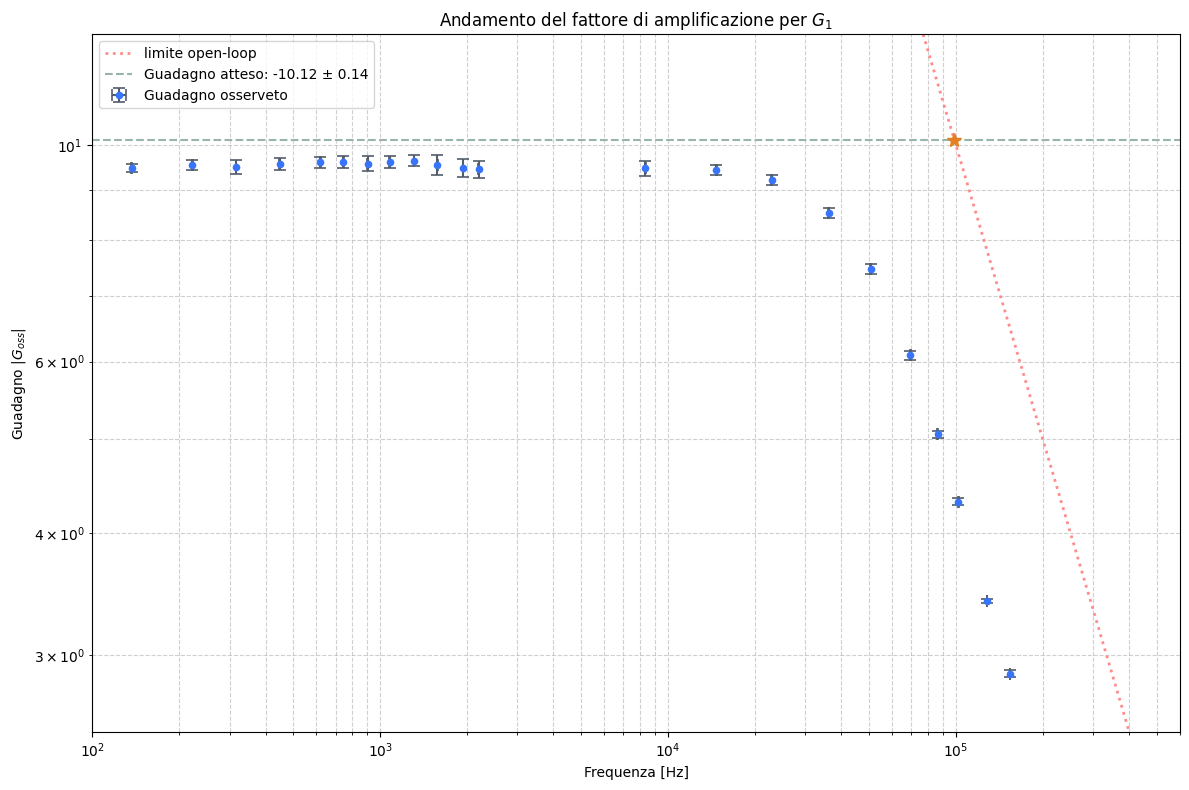

In [17]:
dg10['G_mod']=np.abs(dg10['G_oss'])
f_3dB_teorica=1e6/np.abs(G_1)
f_min_log = np.log10(dg10['freq1 [kHz]'] * 1000).min()
f_max_log = np.log10(dg10['freq1 [kHz]'] * 1000).max()
f_smooth = np.logspace(f_min_log - 0.2, f_max_log + 0.8, 1000)
G_teorico_741 = np.abs(G_1) / np.sqrt(1 + (f_smooth / f_3dB_teorica)**2)
G_asintoto = 10e5 / f_smooth

plt.figure(figsize=(12, 8))
plt.errorbar(dg10['freq1 [kHz]']*1000,dg10['G_mod'],xerr=dg10['devf1 [kHz]']*1000,yerr=np.abs(dg10['devG_oss']), 
                fmt='o',markersize=4.5, color="#3774F9", ecolor="#525c6a", capsize=4, capthick=1.2, label='Guadagno osserveto',zorder=5)
#plt.plot(f_smooth, G_teorico_741, color='#e67e22', linestyle='-', linewidth=2,label=f'Modello teorico')

plt.plot(f_smooth, G_asintoto, color="#ff8b8b", linestyle=':', linewidth=2, label='limite open-loop',zorder=2)

plt.plot(f_3dB_teorica,np.abs(G_1),color='#e67e22',marker='*',markersize=10)

plt.xscale('log')
plt.yscale('log')
plt.axhline(y=np.abs(G_1), color="#316e50ff", linestyle='--', label=f'Guadagno atteso: {G_1:.2f} ± {np.abs(sigma_g1):.2f}',alpha=0.5,zorder=1)
plt.xlabel('Frequenza [Hz]')
plt.ylabel('Guadagno $|G_{oss}|$')
plt.title('Andamento del fattore di amplificazione per $G_1$')
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.xlim(100, 6e5)
plt.ylim(2.5, 13)
plt.tight_layout()
plt.savefig('grafico_G_vs_freq_g10.png')
plt.show()

## II configurazione

In [5]:
R_1=98.7
R_2=2140
sigma_R1=0.1*2+0.008*R_1
sigma_R2=10*2+0.008*R_2

G_2=-R_2/R_1
sigma_g2=G_2*((sigma_R1/R_1)**2+(sigma_R2/R_2)**2)**0.5
print(f"r_1={R_1} ± {sigma_R1}")
print(f"r_2={R_2} ± {sigma_R2}")
print(f"Guadagno atteso: {G_2:.2f} ± {sigma_g2:.2f}")

r_1=98.7 ± 0.9896
r_2=2140 ± 37.120000000000005
Guadagno atteso: -21.68 ± -0.43


| Grandezza | Valore $\pm$ incertezza |
|---|---:|
| $R_1$ [$\Omega$] | $98{,}8 \pm 0{,}99$ |
| $R_2$ [$\Omega$] | $2140 \pm 37$ |
| $G_{att}$ | $-21{,}66 \pm 0{,}43$ |

In [6]:
dati_g_21 = {
    'Vpp1 [V]': [
        0.509, 0.501, 0.507, 0.506, 0.508, 0.507, 0.510, 0.508, 0.508,
        0.504, 0.504, 0.502, 0.503, 0.502, 0.190, 0.196, 0.215, 0.236,
        0.252, 0.267, 0.293, 0.302, 0.308
    ],
    'devVpp1 [V]': [
        0.00527, 0.00539, 0.00449, 0.00616, 0.00577, 0.00637, 0.0128, 0.00624,
        0.00641, 0.00746, 0.00714, 0.00687, 0.00627, 0.00622, 0.00438, 0.00429,
        0.00276, 0.00348, 0.00336, 0.00296, 0.00300, 0.00345, 0.00267
    ],
    'freq1 [kHz]': [
        0.106, 0.140, 0.169, 0.202, 0.252, 0.348, 0.410, 0.510, 0.735,
        0.899, 1.22, 1.59, 1.98, 2.21, 8.42, 12.9, 26.1, 35.9,
        44.0, 53.2, 73.8, 89.9, 109
    ],
    'devf1 [kHz]': [
        0.000510, 0.000442, 0.000620, 0.000765, 0.000998, 0.00180, 0.00228, 0.0142,
        0.00511, 0.00382, 0.00769, 0.00600, 0.00789, 0.00981, 0.0398, 0.0693,
        0.123, 0.173, 0.148, 0.171, 0.305, 0.394, 0.651
    ],
    'Vpp2 [V]': [
        10.7, 10.6, 10.7, 10.4, 10.5, 10.5, 10.5, 10.6, 10.6,
        10.6, 10.6, 10.6, 10.7, 10.7, 3.77, 3.73, 3.45, 3.20,
        2.96, 2.65, 2.12, 1.83, 1.51
    ],
    'devVpp2 [V]': [
        0.0403, 0.0719, 0.0445, 0.0704, 0.00, 0.00, 0.0169, 0.0297,
        0.0382, 0.0177, 0.00585, 0.0234, 0.0396, 0.0380, 0.0189, 0.0213,
        0.0189, 0.00587, 0.0235, 0.0150, 0.00963, 0.0153, 0.00514
    ],
    'fase [°]': [
        -171, -83.8, -135, -157, -176, -173, -175, -175, -176,
        -174, -174, -177, -176, -175, -165, -156, -139, -128,
        -119, -115, -105, -102, -98.1
    ],
    'devfase [°]': [
        49.4, 157, 114, 81.5, 1.45, 1.92, 2.38, 28.9, 1.89,
        1.16, 1.91, 1.32, 1.60, 2.34, 1.51, 2.04, 2.14, 2.69,
        2.22, 2.24, 2.23, 2.38, 2.15
    ],
    '+rate [V/s]': [
        3.70, 1.94, 2.36, 2.75, 3.45, 4.75, 5.50, 3.45, 4.97,
        3.08, 4.20, 2.20, 2.75, 3.09, 0.835, 1.27, 1.16, 1.46,
        0.824, 0.902, 0.993, 1.02, 5.04
    ],
    'dev+rate [V/s]': [
        0.0730, 0.0193, 0.0226, 0.0330, 0.0235, 0.0800, 0.0301, 0.0573,
        0.0835, 0.0242, 0.0304, 0.0211, 0.0328, 0.0196, 0.00857, 0.0158,
        0.0146, 0.0255, 0.0105, 0.0155, 0.0242, 0.0260, 0.0852
    ],
    'cnt': [
        153, 239, 121, 145, 141, 134, 162, 155, 149, 195,
        146, 147, 137, 139, 123, 144, 132, 175, 154, 134,
        148, 142, 173
    ]
}

dg21 = pd.DataFrame(dati_g_21)
dg21.to_csv('dati_g_21.csv', index=False)

# impostiamo le colonne della sdom con (N-1)
for name in ['devVpp1 [V]','devf1 [kHz]','devVpp2 [V]', 'devfase [°]', 'dev+rate [V/s]']:
    dg21[name] = dg21[name]*np.sqrt(dg21['cnt']/(dg21['cnt']-1))

#calcoliamo i campi che ci servono
dg21['G_oss'] = - dg21['Vpp2 [V]'] / dg21['Vpp1 [V]']
dg21['devG_oss'] = dg21['G_oss'] * ((dg21['devVpp1 [V]'] / dg21['Vpp1 [V]'])**2 + (dg21['devVpp2 [V]'] / dg21['Vpp2 [V]'])**2)**0.5

#dg21.to_csv('dati_g_21.csv', index=False)
dg21

,Vpp1 [V],devVpp1 [V],freq1 [kHz],devf1 [kHz],Vpp2 [V],devVpp2 [V],fase [°],devfase [°],+rate [V/s],dev+rate [V/s],cnt,G_oss,devG_oss
0,0.509,0.005287,0.106,0.000512,10.70,0.040432,-171.0,49.562234,3.700,0.073240,153,-21.021611,-0.232364
1,0.501,0.005401,0.140,0.000443,10.60,0.072051,-83.8,157.329486,1.940,0.019341,239,-21.157685,-0.269654
2,0.507,0.004509,0.169,0.000623,10.70,0.044685,-135.0,114.474015,2.360,0.022694,121,-21.104536,-0.207344
3,0.506,0.006181,0.202,0.000768,10.40,0.070644,-157.0,81.782497,2.750,0.033114,145,-20.553360,-0.287287
4,0.508,0.005791,0.252,0.001002,10.50,0.000000,-176.0,1.455169,3.450,0.023584,141,-20.669291,-0.235604
5,0.507,0.006394,0.348,0.001807,10.50,0.000000,-173.0,1.927205,4.750,0.080300,134,-20.710059,-0.261180
6,0.510,0.012840,0.410,0.002287,10.50,0.016952,-175.0,2.387380,5.500,0.030193,162,-20.588235,-0.519391
7,0.508,0.006260,0.510,0.014246,10.60,0.029796,-175.0,28.993679,3.450,0.057486,155,-20.866142,-0.263744
8,0.508,0.006432,0.735,0.005127,10.60,0.038329,-176.0,1.896374,4.970,0.083782,149,-20.866142,-0.274743
9,0.504,0.007479,0.899,0.003830,10.60,0.017746,-174.0,1.162986,3.080,0.024262,195,-21.031746,-0.314084


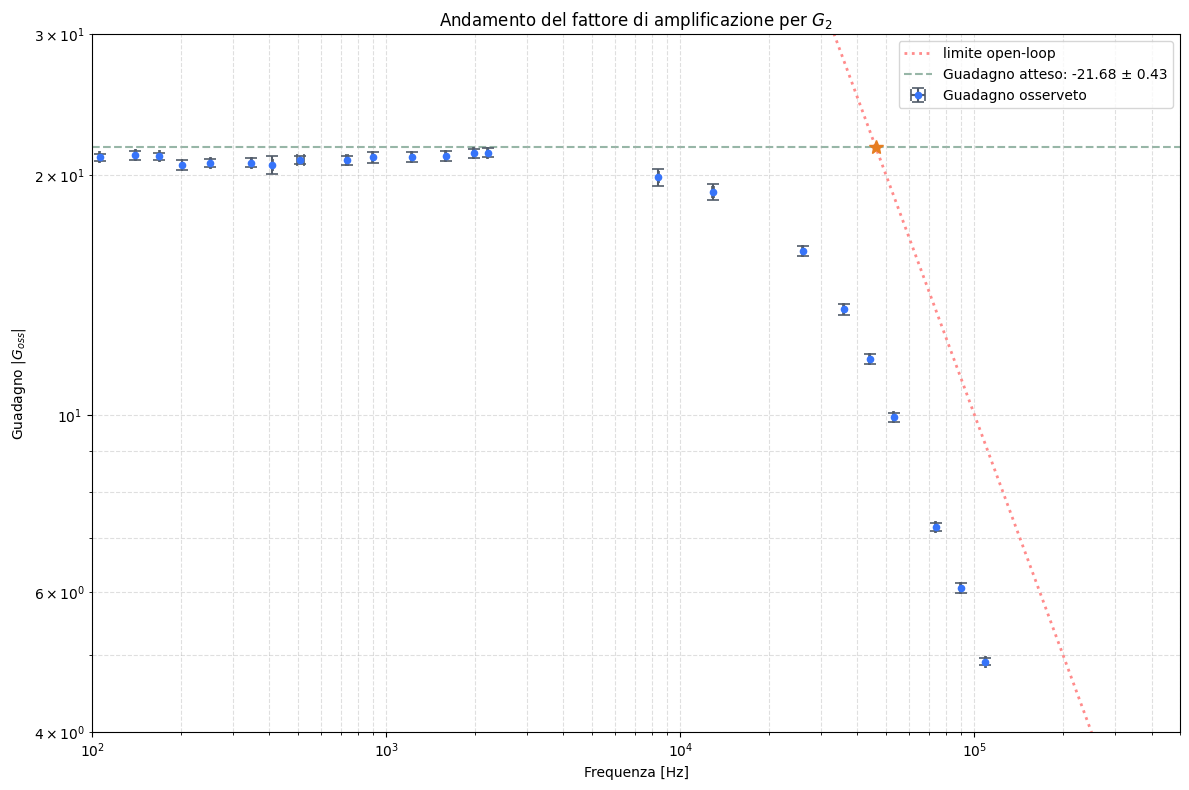

In [16]:
dg21['G_mod']=np.abs(dg21['G_oss'])
f_3dB_teorica=1e6/np.abs(G_2)
f_min_log = np.log10(dg21['freq1 [kHz]'] * 1000).min()
f_max_log = np.log10(dg21['freq1 [kHz]'] * 1000).max()
f_smooth = np.logspace(f_min_log - 0.2, f_max_log + 0.8, 1000)
G_teorico_741 = np.abs(G_2) / np.sqrt(1 + (f_smooth / f_3dB_teorica)**2)
G_asintoto = 10e5 / f_smooth

plt.figure(figsize=(12, 8))
plt.errorbar(dg21['freq1 [kHz]']*1000,dg21['G_mod'],xerr=dg21['devf1 [kHz]']*1000,yerr=np.abs(dg21['devG_oss']), 
                fmt='o',markersize=4.5, color="#3774F9", ecolor="#525c6a", capsize=4, capthick=1.2, label='Guadagno osserveto',zorder=5)
#plt.plot(f_smooth, G_teorico_741, color="#000000", linestyle='-', linewidth=2,label=f'Modello teorico',zorder=2,alpha = 0.3)

plt.plot(f_smooth, G_asintoto, color="#ff8b8b", linestyle=':', linewidth=2, label='limite open-loop',zorder=2)

plt.plot(f_3dB_teorica,np.abs(G_2),color='#e67e22',marker='*',markersize=10)

plt.xscale('log')
plt.yscale('log')
plt.axhline(y=np.abs(G_2), color="#316e50ff", linestyle='--', label=f'Guadagno atteso: {G_2:.2f} ± {np.abs(sigma_g2):.2f}',alpha=0.5,zorder=1)
plt.xlabel('Frequenza [Hz]')
plt.ylabel('Guadagno $|G_{oss}|$')
plt.title('Andamento del fattore di amplificazione per $G_2$')
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.xlim(100, 5e5)
plt.ylim(4, 30)
plt.tight_layout()
plt.savefig('grafico_G_vs_freq_g21.png')
plt.show()

### Circuito derivatore

![schema amplificatore invertente](amp_diff_alot.png)

Per il cortocircuito virtuale ($V_+ = 0\text{ V}$), il nodo invertente è a massa virtuale ($V_- = 0\text{ V}$).

1. La tensione ai capi del condensatore è $V_C = V_{in} - 0 = V_{in}$, quindi la corrente $i_{cap}$ è:
   $$i_{cap} = C \frac{dV_{in}}{dt}$$

2. Poiché l'op-amp non assorbe corrente in ingresso, $i_{cap}$ fluisce interamente nel resistore $R$:
   $$0 - V_{out} = i_{cap} \cdot R \implies V_{out} = -i_{cap} \cdot R$$

3. Sostituendo l'espressione di $i_{cap}$:
   $$\boxed{V_{out}(t) = - R C \frac{dV_{in}(t)}{dt}}$$

In base al segnale applicato all'ingresso, il circuito differenziatore produce forme d'onda in uscita coerenti con le leggi della derivata matematica. Dal punto di vista teorico, ci si attende il seguente comportamento:

* **Onda sinusoidale:** una sinusoide sfasata rispetto al segnale d'ingresso.
* **Onda triangolare:** un'onda quadra o rettangolare.
* **Onda quadra:** una sequenza di picchi impulsivi (*spikes*) in corrispondenza dei fronti d'onda del segnale d'ingresso.

Durante la fase di analisi sperimentale — condotta variando le frequenze e le forme d'onda d'ingresso —, i dati rilevati mostrano segnali d'uscita alterati o disturbati, verosimilmente a causa dell'interazione tra la strumentazione di misura e il circuito stesso.

**Guadagno variabile**

Il circuito in esame presenta una struttura analoga a quella di un amplificatore invertente, in cui la resistenza d'ingresso $R_1$ è sostituita da un'impedenza capacitiva, per sua natura variabile e dipendente dalla frequenza. Questa configurazione suggerisce che anche il fattore di guadagno sarà una funzione della frequenza del segnale. 

In particolare, il modulo del guadagno teorico atteso è espresso dal rapporto tra le impedenze di feedback e di ingresso:

$$G_{att}(\omega) = \left| \frac{V_{out}(\omega)}{V_{in}(\omega)} \right| = \left| \frac{Z_{out}(\omega)}{Z_{in}(\omega)} \right| = \left| \frac{R}{1 / (j\omega C)} \right| = |j\omega RC|$$

Sostituendo la relazione della pulsazione $\omega = 2\pi f$, si ottiene l'andamento analitico del guadagno in funzione della frequenza $f$:

$$\boxed{G_{att}(f) = 2\pi R C f=\frac{f}{f_c}}$$



| Grandezza | Valore $\pm$ incertezza |
|---|---:|
| $R$ [$\Omega$] | $1043 \pm 10$ |
| $C$ [$nF$] | $ 100 \pm 20$ |
| $f_{c}$ $[kHz]$| $1.530 \pm 0{,}034$ |

In [8]:
R=1043
sigma_R=1*2 + 0.008*R
C=100e-9
sigma_C= C*0.02
print(f"R={R} ± {sigma_R}")
print(f"C={C} ± {sigma_C}")
f_taglio=1/(2*np.pi*R*C)
sigma_f_taglio=f_taglio*((sigma_R/R)**2+(sigma_C/C)**2)**0.5
print(f"Frequenza di taglio: {f_taglio:.2e} ± {sigma_f_taglio:.2e}")

R=1043 ± 10.344
C=1e-07 ± 2e-09
Frequenza di taglio: 1.53e+03 ± 3.41e+01


![triangolare](immagini/derivatore/DS1Z_QuickPrint7.png)

In corrispondenza dei fronti di transizione, il segnale d'uscita presenta marcati picchi di sovraelongazione (*overshoot*) seguiti da un leggero *ringing* (oscillazioni smorzate). Tali alterazioni sono riconducibili principalmente alle limitazioni della risposta in frequenza dell'amplificatore operazionale, ai tempi finiti di salita e discesa della strumentazione e agli effetti delle capacità parassite presenti nel circuito reale.

### Onda quadra
![onda quadra](immagini/derivatore/DS1Z_QuickPrint12.png)

Questo grafico mostra cosa succede quando proviamo a far derivare un'onda quadra, che ha dei cambi di tensione istantanei. 

L'onda gialla d'ingresso fa un salto netto, e il circuito (in blu) reagisce creando quei grandi picchi con le ondine che si spengono pian piano (*ringing*). In pratica, l'amplificatore operazionale non riesce a star dietro a una variazione così veloce e "subisce" il colpo, andando per un attimo in risonanza. Si nota anche che persino l'onda gialla d'ingresso si deforma un po' sui bordi a causa della fatica del circuito e della strumentazione.

### Onda sinusoidale

In [9]:
datider = {
    'Vpp1 [V]': [
        0.330, 0.332, 0.331, 0.304, 0.295, 0.235, 0.224, 0.213, 0.186, 0.297,
        0.310
    ],
    'devV1 [V]': [
        0.00, 0.00126, 0.000984, 0.00, 0.00139, 0.0313, 0.000802, 0.00499,
        0.0762, 0.00100, 0.00541
    ],
    'freq [kHz]': [
        0.214, 2.23, 5.10, 11.5, 14.1, 21.2, 22.3, 29.8, 43.4, 98.0, 146
    ],
    'devf [kHz]': [
        0.00, 0.00790, 0.00, 0.0205, 0.00, 0.00411, 0.0792, 27.4, 18.0, 0.00,
        18.1
    ],
    'Vpp2 [V]': [
        0.160, 0.418, 0.883, 2.04, 2.51, 4.06, 4.32, 4.30, 4.35, 1.74, 1.20
    ],
    'devV2 [V]': [
        0.00, 0.00320, 0.00531, 0.00, 0.0139, 0.746, 0.00, 0.776, 1.37, 0.0200,
        0.205
    ],
    'cnt': [2, 6, 11, 7, 9, 154, 6, 201, 29, 3, 17]
}

dder = pd.DataFrame(datider)
# impostiamo le colonne della sdom con (N-1)
for name in ['devV1 [V]','devf [kHz]','devV2 [V]']:
    dder[name] = dder[name]*np.sqrt(dder['cnt']/(dder['cnt']-1))

#calcoliamo i campi che ci servono
dder['G_oss'] = - dder['Vpp2 [V]'] / dder['Vpp1 [V]']
dder['devG_oss'] = dder['G_oss'] * ((dder['devV1 [V]'] / dder['Vpp1 [V]'])**2 + (dder['devV2 [V]'] / dder['Vpp2 [V]'])**2)**0.5

dder.to_csv('dati_derivatore.csv', index=False)
dder

,Vpp1 [V],devV1 [V],freq [kHz],devf [kHz],Vpp2 [V],devV2 [V],cnt,G_oss,devG_oss
0,0.330,0.000000,0.214,0.000000,0.160,0.000000,2,-0.484848,-0.000000
1,0.332,0.001380,2.230,0.008654,0.418,0.003505,6,-1.259036,-0.011785
2,0.331,0.001032,5.100,0.000000,0.883,0.005569,11,-2.667674,-0.018769
3,0.304,0.000000,11.500,0.022143,2.040,0.000000,7,-6.710526,-0.000000
4,0.295,0.001474,14.100,0.000000,2.510,0.014743,9,-8.508475,-0.065619
5,0.235,0.031402,21.200,0.004123,4.060,0.748434,154,-17.276596,-3.933543
6,0.224,0.000879,22.300,0.086759,4.320,0.000000,6,-19.285714,-0.075640
7,0.213,0.005002,29.800,27.468415,4.300,0.777938,201,-20.187793,-3.682935
8,0.186,0.077549,43.400,18.318609,4.350,1.394250,29,-23.387097,-12.299055
9,0.297,0.001225,98.000,0.000000,1.740,0.024495,3,-5.858586,-0.085940


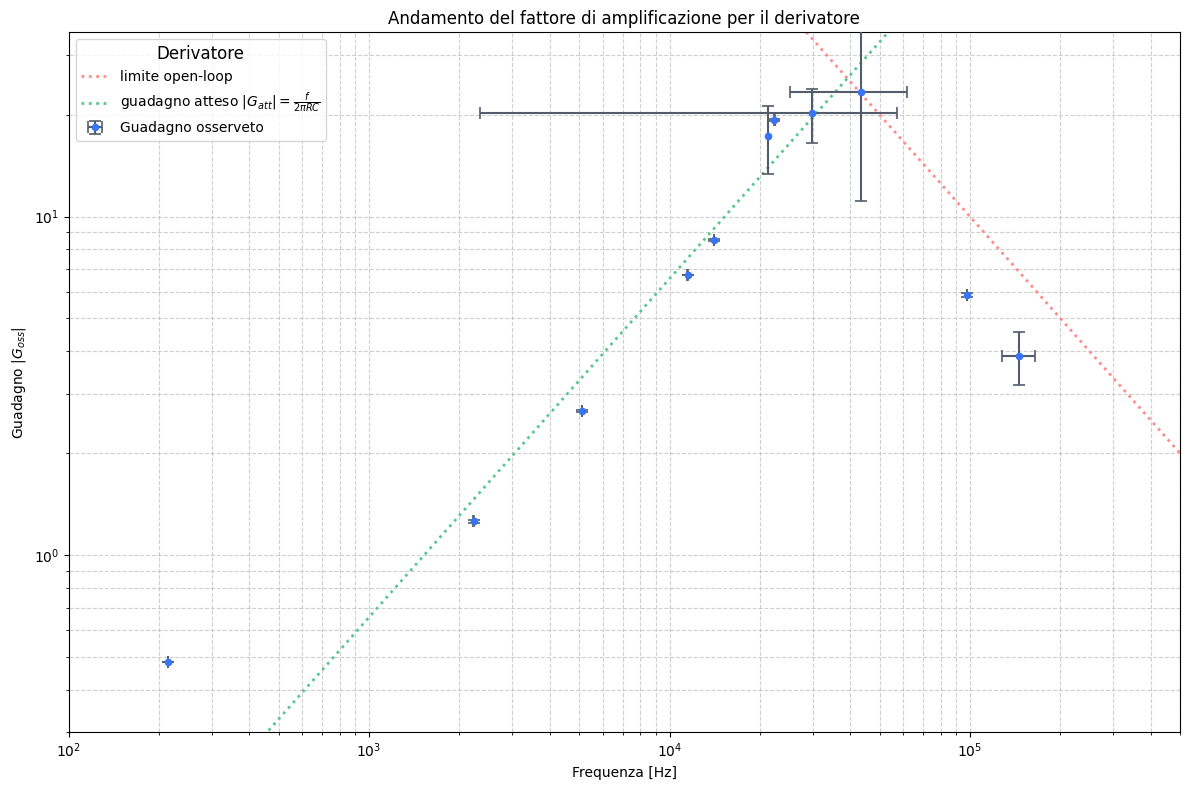

In [19]:
dder['G_mod']=np.abs(dder['G_oss'])
f_3dB_teorica=1e6/np.abs(G_2)
f_min_log = np.log10(dder['freq [kHz]'] * 1000).min()
f_max_log = np.log10(dder['freq [kHz]'] * 1000).max()
f_smooth = np.logspace(f_min_log - 0.2, f_max_log + 0.8, 1000)
G_teorico_741 = np.abs(G_2) / np.sqrt(1 + (f_smooth / f_3dB_teorica)**2)
G_asintoto = 10e5 / f_smooth
G_cond = 1/f_taglio * f_smooth
plt.figure(figsize=(12, 8))
plt.errorbar(dder['freq [kHz]']*1000,dder['G_mod'],xerr=dder['devf [kHz]']*1000,yerr=np.abs(dder['devG_oss']), 
                fmt='o',markersize=4.5, color="#3774F9", ecolor="#525c6a", capsize=4, capthick=1.2, label='Guadagno osserveto',zorder=5)
#plt.scatter(dder['freq [kHz]']*1000,dder['G_mod'], marker='o', color='navy', label='|G_oss| vs Frequenza')
#plt.plot(f_smooth, G_teorico_741, color='darkorange', linestyle='-', linewidth=2,label=f'Modello teorico')

plt.plot(f_smooth, G_asintoto, color='#ff8b8b', linestyle=':', linewidth=2, label='limite open-loop')
plt.plot(f_smooth, G_cond, color="#5ac790ff", linestyle=':', linewidth=2, label=r'guadagno atteso $ |G_{att}| = \frac{f}{2πRC}$')
#plt.plot(f_3dB_teorica,np.abs(G_2),'r*',markersize=10)

plt.xscale('log')
plt.yscale('log')
#plt.axhline(y=np.abs(G_2), color='forestgreen', linestyle='--', label=f'Guadagno atteso: {G_2:.2f} ± {np.abs(sigma_g2):.2f}')
plt.xlabel('Frequenza [Hz]')
plt.ylabel('Guadagno $|G_{oss}|$')
plt.title('Andamento del fattore di amplificazione per il derivatore')
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(title='Derivatore', title_fontsize=12, fontsize=10, loc='upper left')
plt.xlim(100, 5e5)
plt.ylim(0.3, 35)
plt.tight_layout()
plt.savefig('grafico_G_vs_freq_der.png')
plt.show()

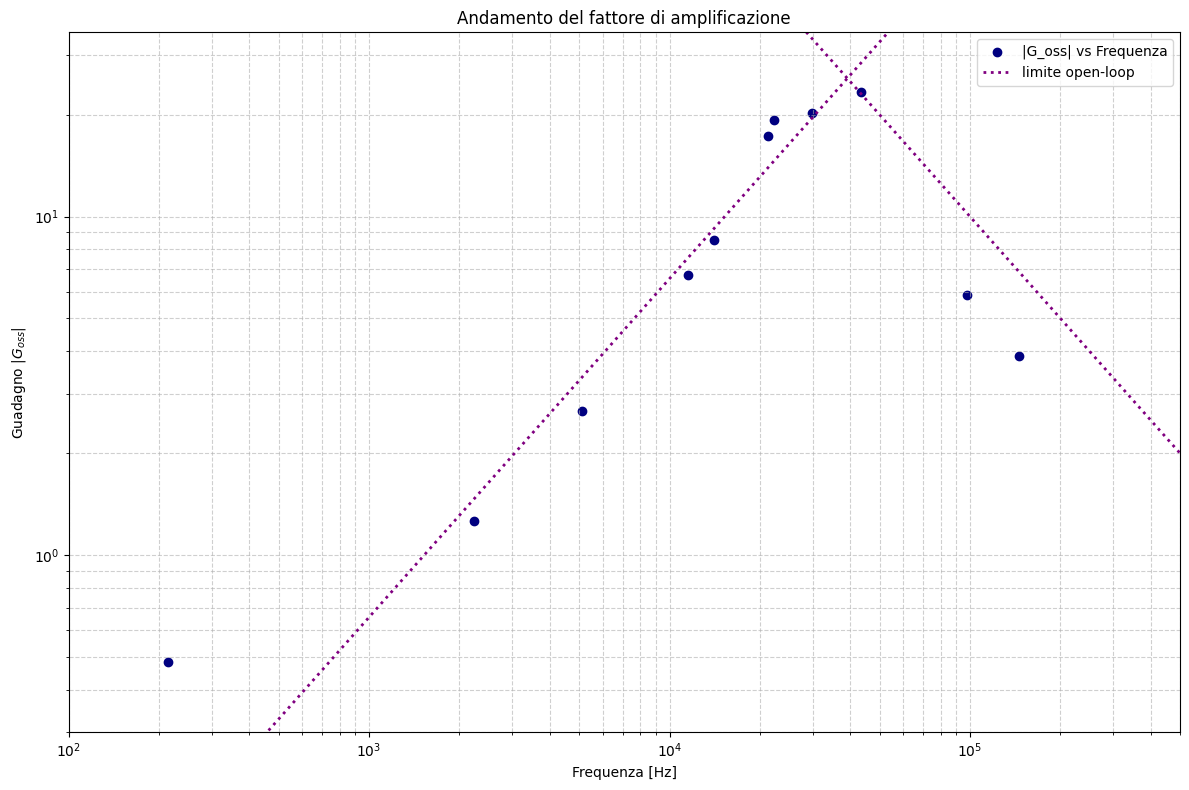

In [11]:
# Configurazione figura e assi logaritmici
plt.figure(figsize=(12, 8))
plt.xscale("log")
plt.yscale("log")

# Dati sperimentali
plt.scatter(
    dder["freq [kHz]"] * 1000,
    dder["G_mod"],
    marker="o",
    color="navy",
    label="|G_oss| vs Frequenza",
)

# Limiti asintotici open-loop
f_smooth = np.logspace(
    np.log10(dder["freq [kHz]"] * 1000).min() - 0.2,
    np.log10(dder["freq [kHz]"] * 1000).max() + 0.8,
    1000,
)
G_asintoto = 10e5 / f_smooth
G_cond = (1 / f_taglio) * f_smooth

plt.plot(
    f_smooth,
    G_asintoto,
    color="purple",
    linestyle=":",
    linewidth=2,
    label="limite open-loop",
)
plt.plot(f_smooth, G_cond, color="purple", linestyle=":", linewidth=2)

# Elementi grafici e salvataggio
plt.xlabel("Frequenza [Hz]")
plt.ylabel("Guadagno $|G_{oss}|$")
plt.title("Andamento del fattore di amplificazione")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.xlim(100, 5e5)
plt.ylim(0.3, 35)
plt.tight_layout()

plt.savefig("grafico_G_vs_freq_derivatore.png")
plt.show()